In [ ]:
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import cohen_kappa_score
warnings.filterwarnings("ignore")
try:
    from google.colab import files      # only used for the download in Cell 8
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

# ---- Read the CSVs that are already in the Colab runtime (left folder panel) ----
RUNTIME_DIR = "/content" if os.path.isdir("/content") else "."

# Leave as None to auto-find by name ("training" / "unseen"),
# or type the exact path, e.g. TRAIN_FILE = "/content/Training_data (90).csv"
TRAIN_FILE = None
TEST_FILE  = None
TOPIC_FILE = None      # optional: CSV with columns record_id, topic (from your own topic model)

def find_file(keyword, exclude=()):
    m = [f for f in sorted(glob.glob(os.path.join(RUNTIME_DIR, "*.csv")))
         if keyword in os.path.basename(f).lower()
         and "predictions" not in os.path.basename(f).lower()
         and f not in exclude]
    return m[0] if m else None

TRAIN_FILE = TRAIN_FILE or find_file("training")
TEST_FILE  = TEST_FILE  or find_file("unseen")
TOPIC_FILE = TOPIC_FILE or find_file("topic", exclude=(TRAIN_FILE, TEST_FILE))

if not (TRAIN_FILE and TEST_FILE):
    raise FileNotFoundError(
        f"Could not find the CSVs in {RUNTIME_DIR}. CSV files there: {glob.glob(os.path.join(RUNTIME_DIR, '*.csv'))}. "
        "Copy the exact names into TRAIN_FILE and TEST_FILE above.")
print("Training:", TRAIN_FILE, "| Unseen:", TEST_FILE, "| Topics:", TOPIC_FILE)

INCLUDE_ARTICLES = True
CLASSES = ["positive", "neutral", "negative"]
COLORS = {"positive": "#2e9e5b", "neutral": "#8a8f98", "negative": "#d64545"}
FINAL_VERSION = "v3_+negation+intensity"     # no labels, so the final version is fixed

def load(path):
    d = pd.read_csv(path)
    d = d.dropna(subset=["text"])
    d = d[d["text"].str.strip() != ""]
    if not INCLUDE_ARTICLES and "record_type" in d.columns:
        d = d[d["record_type"] != "article"]
    return d.reset_index(drop=True)

dev_all, test_all = load(TRAIN_FILE), load(TEST_FILE)
print(f"Training rows: {len(dev_all)} | Unseen rows: {len(test_all)}")

Training: /content/Training data (90%).csv | Unseen: /content/Unseen Data (10%).csv | Topics: None
Training rows: 165 | Unseen rows: 17


In [ ]:
# ---- v1 baseline word list (original, small) ----
SMALL_POS = set("""good great excellent love helpful improve better amazing best thanks thank support free proud
safe benefit progress maganda mahusay magaling salamat mabuti masaya galing tama maayos makakabuti pabor
sana mabait""".split())
SMALL_NEG = set("""bad poor terrible hate worse worst fail useless problem lack crisis corrupt expensive stress
unfair broken shortage pangit masama mahirap kulang palpak sayang hirap mali mahal pagod reklamo
kakulangan bulok""".split())

# ---- v2/v3 expanded word list ----
POS_EN = """good great excellent love loved helpful improve improved improving improvement better amazing best
thanks thank support supported proud safe benefit benefits progress success successful effective wonderful
awesome nice happy glad hope hopeful congratulations congrats recommend valuable quality decent strong
brilliant impressive agree perfect grateful appreciate appreciated deserve opportunity empower inspiring
honest handy correct excited free fair solid smart worth helpful enjoy enjoyed""".split()
NEG_EN = """bad poor terrible hate worse worst fail failed failure useless problem problems lack lacking crisis
corrupt corruption expensive stress stressful unfair broken shortage faulty sad tough struggle struggling
struggled difficult bankrupt deteriorating deteriorate poverty blame blaming limited mediocre downside
ignorant stupid dumb ridiculous shame shameful disappointing disappointed unfortunately issues suffer
suffering victim violence shooting danger dangerous unsafe worry worried angry annoying waste wasted
overpriced outdated flawed incompetent lazy sucks awful horrible pathetic toxic abuse cheating cheat scam
fake bully bullying unemployed underpaid overworked burnout inadequate insufficient neglect weak wrong
sick decline declining lowest harder""".split()
POS_TL = """maganda ganda mahusay husay magaling galing salamat pasalamat mabuti masaya saya tama maayos ayos
makakabuti pabor mabait bait matagumpay tagumpay malinaw linaw tulong bilib hanga mabuhay maasahan
pakinabang swerte sulit tuwa malasakit pagmamahal""".split()
NEG_TL = """pangit masama mahirap hirap kulang palpak sayang mali pagod reklamo kakulangan bulok magnanakaw
nakawan nakaw ninakaw tamad bobo tanga gago buwisit inis galit nakakainis nakakagalit hiya kahihiyan
kawawa pahirap pabaya kapabayaan mababa bumagsak bagsak mahina kahirapan problema suliranin trahedya
sira delikado panganib takot lungkot malungkot sakit iyak abuso korap kurakot kurapsyon kapos gutom
bumaba""".split()
BIG_POS, BIG_NEG = set(POS_EN) | set(POS_TL), set(NEG_EN) | set(NEG_TL)

NEGATORS = {"not","no","never","without","hardly","barely","nothing","hindi","di","wala","walang","ayaw","hinde"}
INTENSIFIERS = {"very","so","really","extremely","super","sobra","talaga","grabe","napaka","sobrang"}
PREFIXES = ["napaka","pinaka","nakaka","magpa","nagpa","mapag","pagka","mag","nag","pag","ma","na","ka","pa"]
SUFFIXES = ["han","hin","an","in"]

def tokenize(text, clean=True):
    text = str(text).lower()
    text = re.sub(r"http\S+|@\w+", " ", text)
    if clean:
        text = re.sub(r"\bud[0-9a-f]{2,4}\b", " ", text)       # emoji escape leftovers (ud83c ...)
        text = re.sub(r"problem[- ]solving", " ", text)         # not a complaint
    return re.findall(r"[a-zñ']+", text)

def word_polarity(tok, pos, neg, stem):
    if tok in pos: return 1.0
    if tok in neg: return -1.0
    if not stem: return 0.0
    cands = set()
    for p in PREFIXES:                      # Tagalog affixes: mahirap/nahirapan -> hirap
        if tok.startswith(p) and len(tok) - len(p) >= 4:
            rest = tok[len(p):]; cands.add(rest)
            for s in SUFFIXES:
                if rest.endswith(s) and len(rest) - len(s) >= 4:
                    cands.add(rest[:-len(s)])
    for c in cands:
        if c in pos: return 1.0
        if c in neg: return -1.0
    return 0.0

class RuleBasedSentiment:
    """score > band -> positive | score < -band -> negative | otherwise -> neutral"""
    def __init__(self, big_lexicon=False, stemming=False, cleaning=False,
                 negation=False, intensifiers=False, neutral_band=0.0):
        self.big, self.stem, self.clean = big_lexicon, stemming, cleaning
        self.neg_on, self.int_on, self.band = negation, intensifiers, neutral_band
        self.pos, self.neg = (BIG_POS, BIG_NEG) if big_lexicon else (SMALL_POS, SMALL_NEG)

    def score(self, text):
        toks, total = tokenize(text, self.clean), 0.0
        for i, t in enumerate(toks):
            s = word_polarity(t, self.pos, self.neg, self.stem)
            if s == 0.0: continue
            window = toks[max(0, i-3):i]
            if self.int_on and any(w in INTENSIFIERS for w in window): s *= 1.5
            if self.neg_on and any(w in NEGATORS for w in window): s *= -1
            total += s
        return total

    def label_from_score(self, sc):
        return "positive" if sc > self.band else "negative" if sc < -self.band else "neutral"
    def predict(self, X): return np.array([self.label_from_score(self.score(t)) for t in X])

VERSIONS = {
    "v1_baseline":            dict(),
    "v2_+lexicon+cleaning":   dict(big_lexicon=True, stemming=True, cleaning=True),
    "v3_+negation+intensity": dict(big_lexicon=True, stemming=True, cleaning=True,
                                   negation=True, intensifiers=True),
}
RULE_CHANGE = {
    "v1_baseline":            "Baseline: original small English+Tagalog word list, plain word matching",
    "v2_+lexicon+cleaning":   "Expanded word list (~270 words), Tagalog affix matching (mahirap/nahirapan -> hirap), "
                              "text cleaning (emoji leftovers, 'problem solving'), dropped 'sana'/'mahal'",
    "v3_+negation+intensity": "Negation (3-word window flips polarity) + intensifiers (x1.5)",
}
final_clf = RuleBasedSentiment(**VERSIONS[FINAL_VERSION])

,Version,Dataset,n,positive %,neutral %,negative %,positive (n),neutral (n),negative (n)
0,v1_baseline,training,165,37.6,53.9,8.5,62,89,14
1,v1_baseline,unseen,17,41.2,58.8,0.0,7,10,0
2,v2_+lexicon+cleaning,training,165,40.0,40.0,20.0,66,66,33
3,v2_+lexicon+cleaning,unseen,17,41.2,47.1,11.8,7,8,2
4,v3_+negation+intensity,training,165,37.6,41.2,21.2,62,68,35
5,v3_+negation+intensity,unseen,17,52.9,35.3,11.8,9,6,2


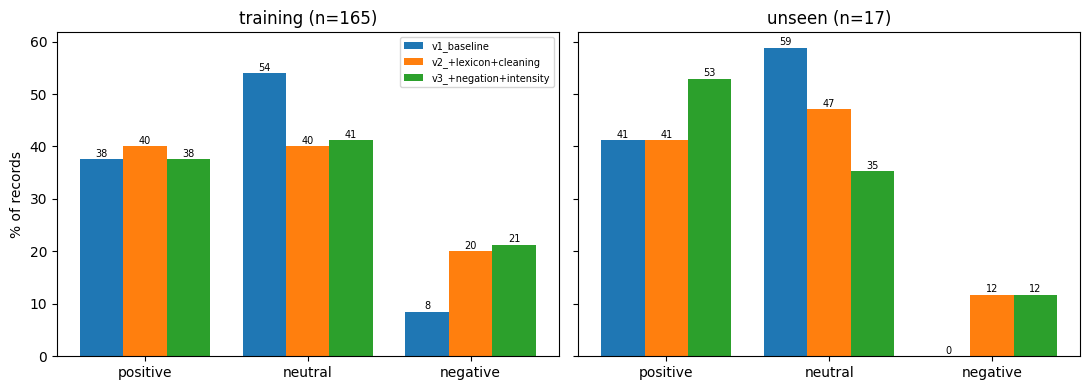

In [ ]:
preds = {n: {"training": RuleBasedSentiment(**p).predict(dev_all["text"].values),
             "unseen":   RuleBasedSentiment(**p).predict(test_all["text"].values)}
         for n, p in VERSIONS.items()}

def share(arr):
    return pd.Series(arr).value_counts(normalize=True).reindex(CLASSES, fill_value=0) * 100

rows = []
for n in VERSIONS:
    for ds in ("training", "unseen"):
        s = share(preds[n][ds]); cnt = pd.Series(preds[n][ds]).value_counts().reindex(CLASSES, fill_value=0)
        rows.append({"Version": n, "Dataset": ds, "n": len(preds[n][ds]),
                     **{f"{c} %": round(s[c], 1) for c in CLASSES},
                     **{f"{c} (n)": int(cnt[c]) for c in CLASSES}})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, ("training", "unseen")):
    w, x = 0.8 / len(VERSIONS), np.arange(3)
    for k, n in enumerate(VERSIONS):
        s = share(preds[n][ds]); bars = ax.bar(x + k*w, s.values, w, label=n)
        for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f"{b.get_height():.0f}", ha="center", fontsize=7)
    ax.set_xticks(x + w); ax.set_xticklabels(CLASSES); ax.set_title(f"{ds} (n={len(preds[n][ds])})")
axes[0].set_ylabel("% of records"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Predicted class share per fold (v3_+negation+intensity)


,Fold,n,positive %,neutral %,negative %
0,1,17,47.1,35.3,17.6
1,2,17,23.5,52.9,23.5
2,3,17,29.4,41.2,29.4
3,4,17,35.3,47.1,17.6
4,5,17,41.2,35.3,23.5
5,6,16,25.0,56.2,18.8
6,7,16,43.8,37.5,18.8
7,8,16,56.2,31.2,12.5
8,9,16,37.5,25.0,37.5
9,10,16,37.5,50.0,12.5


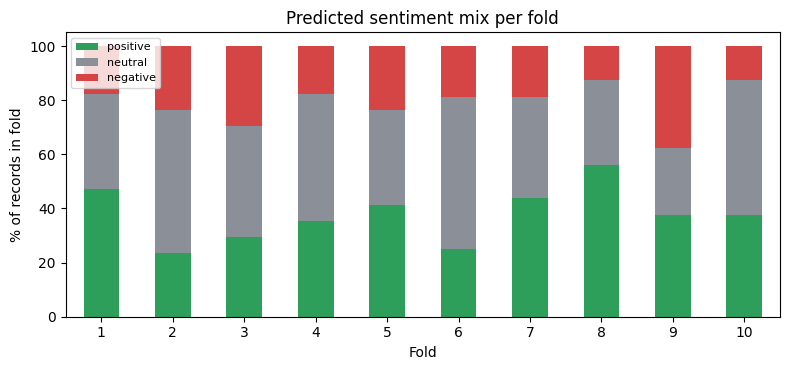

In [ ]:
# The model has no trained parameters, so each fold is just a subset of the training data.
# This shows how stable the predicted class mix is; it is NOT an accuracy measure.
n_splits = min(10, len(dev_all))
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
X = dev_all["text"].values
rows = []
for k, (tr, va) in enumerate(kf.split(X), 1):
    s = share(final_clf.predict(X[va]))
    rows.append({"Fold": k, "n": len(va), **{f"{c} %": round(s[c], 1) for c in CLASSES}})
fold_df = pd.DataFrame(rows)
summ = {"Fold": "mean ± SD", "n": int(fold_df["n"].sum())}
summ.update({f"{c} %": f"{fold_df[f'{c} %'].mean():.1f} ± {fold_df[f'{c} %'].std():.1f}" for c in CLASSES})
print(f"Predicted class share per fold ({FINAL_VERSION})")
display(pd.concat([fold_df, pd.DataFrame([summ])], ignore_index=True))

ax = fold_df.set_index("Fold")[[f"{c} %" for c in CLASSES]].plot(
    kind="bar", stacked=True, figsize=(8, 3.8), color=[COLORS[c] for c in CLASSES])
ax.set_ylabel("% of records in fold"); ax.set_title("Predicted sentiment mix per fold")
ax.legend([c for c in CLASSES], fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [ ]:
names = list(VERSIONS)
all_text = np.concatenate([dev_all["text"].values, test_all["text"].values])
all_pred = {n: np.concatenate([preds[n]["training"], preds[n]["unseen"]]) for n in names}

rows, prev = [], None
for n in names:
    s = share(all_pred[n])
    row = {"Version": n, "Rule change": RULE_CHANGE[n], **{f"{c} %": round(s[c], 1) for c in CLASSES}}
    if prev is None:
        row["% predictions changed"] = "-"; row["Agreement (kappa)"] = "-"
    else:
        row["% predictions changed"] = f"{(all_pred[n] != all_pred[prev]).mean():.1%}"
        row["Agreement (kappa)"] = round(cohen_kappa_score(all_pred[prev], all_pred[n]), 3)
    rows.append(row); prev = n
display(pd.DataFrame(rows))

first, last = names[0], names[-1]
print(f"\nHow predictions moved from {first} to {last} (rows = {first}, columns = {last}):")
display(pd.crosstab(pd.Series(all_pred[first], name=first), pd.Series(all_pred[last], name=last))
        .reindex(index=CLASSES, columns=CLASSES, fill_value=0))

changed = np.where(all_pred[first] != all_pred[last])[0]
ex = pd.DataFrame({"text": [all_text[i][:110] for i in changed],
                   first: all_pred[first][changed], last: all_pred[last][changed]})
print(f"\nExamples of rows whose label changed ({len(changed)} in total) - check whether the change is an improvement:")
display(ex.head(15))

,Version,Rule change,positive %,neutral %,negative %,% predictions changed,Agreement (kappa)
0,v1_baseline,"Baseline: original small English+Tagalog word list, plain word matching",37.9,54.4,7.7,-,-
1,v2_+lexicon+cleaning,"Expanded word list (~270 words), Tagalog affix matching (mahirap/nahirapan -> hirap), text clean...",40.1,40.7,19.2,25.8%,0.578
2,v3_+negation+intensity,Negation (3-word window flips polarity) + intensifiers (x1.5),39.0,40.7,20.3,5.5%,0.914



How predictions moved from v1_baseline to v3_+negation+intensity (rows = v1_baseline, columns = v3_+negation+intensity):


v3_+negation+intensity,positive,neutral,negative
v1_baseline,,,
positive,55,4,10
neutral,15,67,17
negative,1,3,10



Examples of rows whose label changed (50 in total) - check whether the change is an improvement:


,text,v1_baseline,v3_+negation+intensity
0,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kaila...,positive,negative
1,i think people are being overly critical in his statement my point naman siya may mga matatalino...,positive,neutral
2,we already had essay-type questions back when i was in grade i remember struggling a lot with th...,neutral,negative
3,sa tawi tawi ma develop sana,positive,neutral
4,education secretary sonny angara is urging congress to restore funding for the government s lear...,positive,negative
5,catholic education authorities are calling for the immediate release of delayed government vouch...,neutral,positive
6,let's address the elephant in the room bukod sa bumaba rankings natin from to - no ph school ran...,neutral,negative
7,like the other person said classes are mostly taught in english ateneo specifically has a progra...,positive,neutral
8,the problem of the deteriorating quality of philippine education as well as the poverty in the p...,neutral,negative
9,the things i love about this that the video showcases the adaptability of the danish people if s...,positive,negative


In [ ]:
tr_s, un_s = share(preds[FINAL_VERSION]["training"]), share(preds[FINAL_VERSION]["unseen"])
cmp = pd.DataFrame({"training %": tr_s.round(1), "unseen %": un_s.round(1),
                    "difference (unseen - training)": (un_s - tr_s).round(1)})
display(cmp)

try:
    from scipy.stats import chi2_contingency
    table = np.array([[(preds[FINAL_VERSION][ds] == c).sum() for c in CLASSES] for ds in ("training", "unseen")])
    p = chi2_contingency(table)[1]
    print(f"Chi-square test of equal sentiment mix: p = {p:.3f}")
    print("-> No significant difference: the model behaves similarly on unseen data." if p > 0.05
          else "-> The mix differs significantly between training and unseen data.")
except Exception as e:
    print("Chi-square test skipped:", e)
print(f"Caution: the unseen set has only {len(test_all)} rows, so small differences are noise. "
      "This compares prediction behavior, not correctness; without labels, accuracy on unseen data is unknown.")

,training %,unseen %,difference (unseen - training)
positive,37.6,52.9,15.4
neutral,41.2,35.3,-5.9
negative,21.2,11.8,-9.4


Chi-square test of equal sentiment mix: p = 0.419
-> No significant difference: the model behaves similarly on unseen data.
Caution: the unseen set has only 17 rows, so small differences are noise. This compares prediction behavior, not correctness; without labels, accuracy on unseen data is unknown.


No topic assignments found, so fitting a simple NMF topic model with 5 topics (upload a topics CSV with record_id,topic to use your own topic model).

Counts per topic:


predicted_label,positive,neutral,negative,total
topic,,,,
"T1: education, pisa, learning, said",14,14,9,37
"T2: thank, sir, lord, watching",13,5,0,18
"T3: school, students, high, teachers",35,32,21,88
"T4: universities, chinese, teachers, citizens",9,13,7,29
"T5: big, start, pala, saying",0,7,0,7
Unassigned,0,3,0,3


Share (%) per topic:


predicted_label,positive,neutral,negative
topic,,,
"T1: education, pisa, learning, said",37.8,37.8,24.3
"T2: thank, sir, lord, watching",72.2,27.8,0.0
"T3: school, students, high, teachers",39.8,36.4,23.9
"T4: universities, chinese, teachers, citizens",31.0,44.8,24.1
"T5: big, start, pala, saying",0.0,100.0,0.0
Unassigned,0.0,100.0,0.0


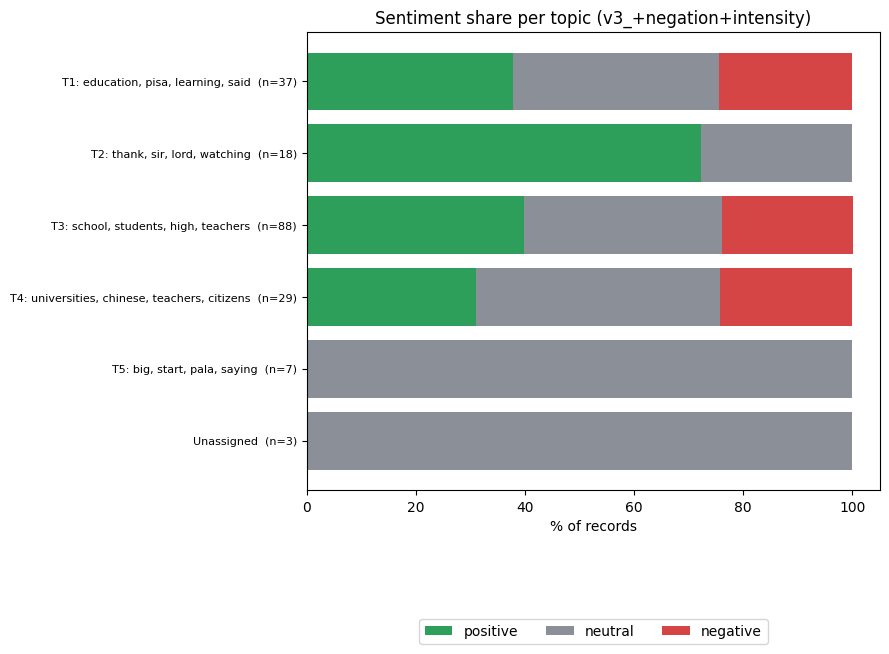

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

all_df = pd.concat([dev_all.assign(dataset="training"), test_all.assign(dataset="unseen")], ignore_index=True)
all_df["sentiment_score"] = [final_clf.score(t) for t in all_df["text"]]
all_df["predicted_label"] = [final_clf.label_from_score(s) for s in all_df["sentiment_score"]]

N_TOPICS = 5     # used only when you have no topic assignments of your own
TL_STOP = set("""ang ng sa na mga ay at ko mo po ito yung nang para pero kung naman lang din rin ba ni si kay nito
niya sila kami tayo namin natin kayo ninyo iyan iyon yan ung nga pa opo wala may meron dahil kasi pag mag
glance filipino philippines deped""".split())

if "topic" in all_df.columns:
    print("Using the 'topic' column found in your CSV.")
elif TOPIC_FILE:
    tp = pd.read_csv(TOPIC_FILE)[["record_id", "topic"]].drop_duplicates("record_id")
    all_df = all_df.merge(tp, on="record_id", how="left")
    all_df["topic"] = all_df["topic"].fillna("Unassigned").astype(str)
    print("Using topics from", TOPIC_FILE)
else:
    print(f"No topic assignments found, so fitting a simple NMF topic model with {N_TOPICS} topics "
          "(upload a topics CSV with record_id,topic to use your own topic model).")
    def topic_text(t):
        t = re.sub(r"http\S+|@\w+", " ", str(t).lower())
        return re.sub(r"\bud[0-9a-f]{2,4}\b", " ", t)
    vec = TfidfVectorizer(preprocessor=topic_text, token_pattern=r"\b[a-zñ]{3,}\b",
                          stop_words=list(ENGLISH_STOP_WORDS | TL_STOP), max_df=0.8, min_df=2)
    X_train = vec.fit_transform(dev_all["text"])
    nmf = NMF(n_components=N_TOPICS, init="nndsvda", random_state=42, max_iter=500).fit(X_train)
    W = nmf.transform(vec.transform(all_df["text"]))
    vocab = np.array(vec.get_feature_names_out())
    tnames = [f"T{k+1}: " + ", ".join(vocab[np.argsort(nmf.components_[k])[::-1][:4]]) for k in range(N_TOPICS)]
    all_df["topic"] = [tnames[i] if W[j].sum() > 0 else "Unassigned" for j, i in enumerate(W.argmax(axis=1))]

ct = pd.crosstab(all_df["topic"], all_df["predicted_label"]).reindex(columns=CLASSES, fill_value=0)
ct["total"] = ct.sum(axis=1)
pct = (ct[CLASSES].div(ct["total"], axis=0) * 100).round(1)
print("\nCounts per topic:");  display(ct)
print("Share (%) per topic:"); display(pct)

fig, ax = plt.subplots(figsize=(9, 0.9*len(pct) + 1.5))
left = np.zeros(len(pct))
for c in CLASSES:
    ax.barh(range(len(pct)), pct[c], left=left, color=COLORS[c], label=c); left += pct[c].values
ax.set_yticks(range(len(pct))); ax.set_yticklabels([f"{t}  (n={ct.loc[t,'total']})" for t in pct.index], fontsize=8)
ax.set_xlabel("% of records"); ax.set_title(f"Sentiment share per topic ({FINAL_VERSION})")
ax.invert_yaxis(); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout(); plt.show()

In [ ]:
keep = [c for c in ["record_id", "platform", "record_type", "detected_language", "dataset", "topic",
                    "text", "sentiment_score", "predicted_label"] if c in all_df.columns]
all_df[keep].to_csv("predictions_all.csv", index=False)
print("Saved predictions_all.csv with", len(all_df), "rows")
if IN_COLAB:
    files.download("predictions_all.csv")

Saved predictions_all.csv with 182 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>